# Notebook 01 — Selección espacial de estaciones candidatas

**TFM:** Evaluación de la influencia del componente espacial en la estimación de datos faltantes de precipitación diaria mediante modelos de Machine Learning aplicados a estaciones meteorológicas.



## 1 - Objetivo del notebook

Este notebook parte de un **punto de interés** de la zona de estudio y selecciona estaciones de precipitación cercanas a partir del **CATÁLOGO NACIONAL DE ESTACIONES** extraídas del geoportal Datos Hidrológicos y Meteorológicos (DHIME) creado por El Instituto de Hidrología, Meteorología y Estudios Ambientales **(IDEAM)**


La salida principal de este primer notebook será una tabla de **estaciones candidatas**, la cual servirá como entrada para el Notebook 02, donde se descargará la precipitación de dichas estaciones.



### 1.2  - Flujo

1. Definir punto de interés.
2. Consultar estaciones con registros de precipitación en Socrata.
3. Limpiar coordenadas.
4. Calcular distancia al punto de interés.
5. Seleccionar estaciones candidatas.
6. Guardar archivos intermedios para los siguientes notebooks.

## 2 - instalación de Librerias

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 3 - Detectar carpetas del proyecto

---
> ℹ️ **Información**
>
> A continuación se construye la estructura de archivos a manejar en el proyecto

In [ ]:
# Importamos la librería necesaria para el manejo de archivos

from pathlib import Path


# identificamos el nombre de la carpeta actual
carpeta_actual = Path.cwd()


# Comparamos si la carpeta actual hace parte de las carpetas del proyecto con el objetivo de encontrar la carpeta raiz
if carpeta_actual.name == 'notebooks':
    PROJECT_ROOT = carpeta_actual.parent
else:
    PROJECT_ROOT = carpeta_actual

# una vez determinada la capeta raiz 'PROJECT_ROOT' contruimos las demás carpetas del proyecto


folders = [
    PROJECT_ROOT / "data" / "raw"/ "catalogo_estaciones_DHIME",
    PROJECT_ROOT / "data" / "intermediate",
    PROJECT_ROOT / "data" / "processed",
    PROJECT_ROOT / "notebooks",
    PROJECT_ROOT / "output" / "tables",
    PROJECT_ROOT / "output" / "figures",
    PROJECT_ROOT / "scr"
]

# Con el siguiente bucle se crean de manera segura los directorios del proyecto

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True) # Parent = True crea las carpetas parent intermedias / exist_ok ignora las carpetas existentes

## 4 - Importar información Base

### 4.1 - Detectar Punto de interés

---

Las coordenadas de este punto son tomadas con ayuda de Google Maps
[Punto sobre el río Arzobispo](https://maps.app.goo.gl/1WaW8gaS2cM9JEMo8)

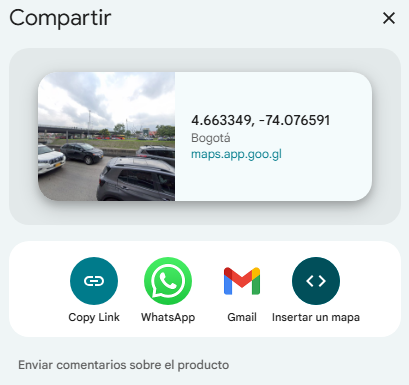

In [ ]:
# Punto de interés / coordenadas extraídas desde google Maps sobre territorio Colombiano
LATITUD = 4.663349
LONGITUD = -74.076591
punto_WKT = f"POINT ({LONGITUD} {LATITUD})"
print(punto_WKT)


POINT (-74.076591 4.663349)


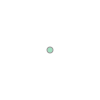

In [ ]:
from shapely import Point # https://shapely.readthedocs.io/en/stable/geometry.html

punto_de_interes = Point(LONGITUD, LATITUD)
punto_de_interes




### 4.2 - Importar el catálogo de estaciones

Este catálogo se descarga en formato Shape File (.shp) el cual permite crear directamente el GeoDataFrame.

**Fuente:** IDEAM – DHIME, *Catálogo Nacional de Estaciones*, Consulta y Descarga de Datos Hidrometeorológicos, recursos `Catalogo Nacional de Estaciones`.

[Consultar fuente](https://atencionciudadano.ideam.gov.co). Consulta: agosto de 2026.


In [ ]:
ruta_catalogo_estaciones =  PROJECT_ROOT / "data" / "raw"/ "catalogo_estaciones_DHIME" / "CNE_IDEAM.zip"
gdf_catalogo_estaciones = gpd.read_file(ruta_catalogo_estaciones)
gdf_catalogo_estaciones.head()

,CODIGO,nombre,CATEGORIA,TECNOLOGIA,ESTADO,FECHA_INST,altitud,latitud,longitud,DEPARTAMEN,...,d_TECNOLOG,d_ESTADO,d_DEPARTAM,d_MUNICIPI,d_AREA_OPE,d_AREA_HID,d_ZONA_HID,d_CORRIENT,d_SUBZONA_,geometry
0,2904000176,UNIREFORMADA - AUT [2904000176],CP,TEST001,ESTA001,2021-12-10,99.0,10.985250,-74.815928,8.0,...,Automática con Telemetría,Activa,Atlantico,Barranquilla,Area Operativa 02 - Atlántico-Bolivar-Sucre,Magdalena Cauca,Bajo Magdalena,None,Directos al Bajo Magdalena entre Calamar y des...,POINT (-74.81593 10.98525)
1,2904000177,UNIAUTONOMA - AUT [2904000177],CP,TEST001,ESTA001,2021-12-10,110.0,11.004000,-74.824008,8.0,...,Automática con Telemetría,Activa,Atlantico,Barranquilla,Area Operativa 02 - Atlántico-Bolivar-Sucre,Magdalena Cauca,Bajo Magdalena,None,Directos al Bajo Magdalena entre Calamar y des...,POINT (-74.82401 11.004)
2,29040240,USIACURI [29040240],PM,TEST003,ESTA001,1964-02-15,100.0,10.744722,-74.980556,8.0,...,Convencional,Activa,Atlantico,Usiacurí,Area Operativa 02 - Atlántico-Bolivar-Sucre,Magdalena Cauca,Bajo Magdalena,None,Canal del Dique margen derecho,POINT (-74.98056 10.74472)
3,48015040,PUERTO NARIÑO [48015040],CP,"TEST001,TEST003",ESTA001,2005-07-19,158.0,-3.780152,-70.362447,91.0,...,"Automática con Telemetría,Convencional",Activa,Amazonas,Puerto Nariño,Area Operativa 11 - Cundinamarca-Amazonas-San ...,Amazonas,Amazonas - Directos,None,Directos Río Amazonas (mi),POINT (-70.36245 -3.78015)
4,2119500208,SUMAPAZ (CUEVECITAS) [2119500208],ME,TEST002,ESTA002,2021-12-01,3652.0,4.215075,-74.250300,25.0,...,Automática sin Telemetría,Suspendida,Cundinamarca,Pasca,Area Operativa 11 - Cundinamarca-Amazonas-San ...,Magdalena Cauca,Alto Magdalena,None,Río Sumapaz,POINT (-74.2503 4.21508)


In [ ]:
gdf_catalogo_estaciones.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 4526 entries, 0 to 4525
Data columns (total 31 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   CODIGO      4526 non-null   object        
 1   nombre      4526 non-null   object        
 2   CATEGORIA   4526 non-null   object        
 3   TECNOLOGIA  4526 non-null   object        
 4   ESTADO      4526 non-null   object        
 5   FECHA_INST  4526 non-null   datetime64[ms]
 6   altitud     4526 non-null   float64       
 7   latitud     4526 non-null   float64       
 8   longitud    4526 non-null   float64       
 9   DEPARTAMEN  4526 non-null   float64       
 10  MUNICIPIO   4526 non-null   float64       
 11  AREA_OPERA  4526 non-null   float64       
 12  AREA_HIDRO  4526 non-null   float64       
 13  ZONA_HIDRO  4526 non-null   float64       
 14  CORRIENTE   4526 non-null   float64       
 15  FECHA_SUSP  2002 non-null   datetime64[ms]
 16  SUBZONA_HI  4526

### 4.3 - Comprobación Coordenadas

A continuación, se hace la verificación del Origen de coordenadas del catálogo de estaciones.

In [ ]:
gdf_catalogo_estaciones.crs

<Geographic 2D CRS: EPSG:4686>
Name: MAGNA-SIRGAS
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: Colombia - onshore and offshore. Includes San Andres y Providencia, Malpelo Islands, Roncador Bank, Serrana Bank and Serranilla Bank.
- bounds: (-84.77, -4.23, -66.87, 15.51)
Datum: Marco Geocentrico Nacional de Referencia
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

Las coordenadas tomadas de Google Maps para cualquier lugar de Colombia (en formato de latitud y longitud decimal) utilizan el sistema global WGS 84, cuyo código EPSG es EPSG:4326

In [ ]:
from shapely.ops import transform
import pyproj

# 1. Definir el transformador de origen a destino (ej. WGS 84 a Magna-SIRGAS / Bogotá)
origen = "EPSG:4326"
destino = "EPSG:9377"
proyectar = pyproj.Transformer.from_crs(origen, destino, always_xy=True).transform

# 2. Reproyectar el punto
punto_reproyectado = transform(proyectar, punto_de_interes)

print(punto_reproyectado.x, punto_reproyectado.y)

4880637.115604961 2073386.0430808694


## 5 - Transformar a un CRS proyectado

Las coordenadas tomadas de Google Maps para cualquier lugar de Colombia (en formato de latitud y longitud decimal) utilizan el sistema global WGS 84, cuyo código EPSG es EPSG:4326

Para calcular distancias de forma precisa, es necesario que ambos GeoDataFrames (`punto_de_interes` y `gdf_catalogo_estaciones`) estén en el mismo Sistema de Referencia de Coordenadas (CRS) y que este sea proyectado (que utilice unidades lineales como metros). Se utilizará el CRS `EPSG:9377` [MAGNA-SIRGAS 2018 / Origen-Nacional](https://epsg.io/9377)

In [ ]:
from shapely.ops import transform
import pyproj

# 1. Definir el transformador de origen a destino (ej. MAGNA-SIRGAS 2018 / Origen Nacional)
origen = "EPSG:4326"
destino = "EPSG:9377"
proyectar = pyproj.Transformer.from_crs(origen, destino, always_xy=True).transform

# 2. Reproyectar el punto
punto_reproyectado = transform(proyectar, punto_de_interes)

# 3. Transformar el GeoDataFrame del catálogo de estaciones al CRS objetivo
gdf_catalogo_estaciones_proj = gdf_catalogo_estaciones.to_crs(destino)

print(f"CRS del punto de interés (proyectado): {destino}")
print(f"CRS del catálogo de estaciones (proyectado): {gdf_catalogo_estaciones_proj.crs}")



CRS del punto de interés (proyectado): EPSG:9377
CRS del catálogo de estaciones (proyectado): EPSG:9377


In [ ]:
gdf_catalogo_estaciones_proj["distancia_m"] = gdf_catalogo_estaciones_proj.distance(punto_reproyectado)
gdf_estaciones = gdf_catalogo_estaciones_proj.sort_values("distancia_m",ascending=True)
gdf_estaciones.head()

,CODIGO,nombre,CATEGORIA,TECNOLOGIA,ESTADO,FECHA_INST,altitud,latitud,longitud,DEPARTAMEN,...,d_ESTADO,d_DEPARTAM,d_MUNICIPI,d_AREA_OPE,d_AREA_HID,d_ZONA_HID,d_CORRIENT,d_SUBZONA_,geometry,distancia_m
1493,21206190,UNIV PEDAGOGICA [21206190],CO,TEST003,ESTA002,1986-11-15,2570.0,4.666667,-74.066667,11.0,...,Suspendida,Bogotá,"Bogota, D.C",Area Operativa 11 - Cundinamarca-Amazonas-San ...,Magdalena Cauca,Alto Magdalena,San Juan,Río Bogotá,POINT (4881738.12 2073751.012),1159.919151
2366,21205800,BOMBEROS DEL NORTE [21205800],ME,TEST003,ESTA002,1972-11-15,2560.0,4.650000,-74.066667,11.0,...,Suspendida,Bogotá,"Bogota, D.C",Area Operativa 11 - Cundinamarca-Amazonas-San ...,Magdalena Cauca,Alto Magdalena,Seco,Río Bogotá,POINT (4881735.334 2071909.143),1840.467104
4078,21205529,SOLMAFORO BOGOTA - [21205529],AB,TEST002,ESTA002,2015-12-03,2562.0,4.667542,-74.060447,11.0,...,Suspendida,Bogotá,"Bogota, D.C",Area Operativa 11 - Cundinamarca-Amazonas-San ...,Magdalena Cauca,Alto Magdalena,None,Río Bogotá,POINT (4882427.897 2073846.669),1849.074131
3963,21205710,JARDIN BOTANICO [21205710],CP,"TEST001,TEST003",ESTA001,1974-09-15,2552.0,4.667867,-74.101034,11.0,...,Activa,Bogotá,"Bogota, D.C",Area Operativa 11 - Cundinamarca-Amazonas-San ...,Magdalena Cauca,Alto Magdalena,None,Río Bogotá,POINT (4877927.545 2073889.531),2755.952395
3635,21206040,ESAP [21206040],ME,TEST003,ESTA002,1985-04-15,2553.0,4.646778,-74.096361,11.0,...,Suspendida,Bogotá,"Bogota, D.C",Area Operativa 11 - Cundinamarca-Amazonas-San ...,Magdalena Cauca,Alto Magdalena,Seco,Río Bogotá,POINT (4878442.073 2071558.084),2856.509347


In [ ]:
gdf_catalogo_estaciones_proj.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 4526 entries, 0 to 4525
Data columns (total 32 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   CODIGO       4526 non-null   object        
 1   nombre       4526 non-null   object        
 2   CATEGORIA    4526 non-null   object        
 3   TECNOLOGIA   4526 non-null   object        
 4   ESTADO       4526 non-null   object        
 5   FECHA_INST   4526 non-null   datetime64[ms]
 6   altitud      4526 non-null   float64       
 7   latitud      4526 non-null   float64       
 8   longitud     4526 non-null   float64       
 9   DEPARTAMEN   4526 non-null   float64       
 10  MUNICIPIO    4526 non-null   float64       
 11  AREA_OPERA   4526 non-null   float64       
 12  AREA_HIDRO   4526 non-null   float64       
 13  ZONA_HIDRO   4526 non-null   float64       
 14  CORRIENTE    4526 non-null   float64       
 15  FECHA_SUSP   2002 non-null   datetime64[ms]
 16

In [ ]:
NUMERO_ESTACIONES_CANDIDATAS = 20

In [ ]:
gdf_catalogo_estaciones_proj["distancia_km"] = gdf_catalogo_estaciones_proj["distancia_m"]/1000
estaciones_cercanas = gdf_catalogo_estaciones_proj.sort_values(by ="distancia_km",ascending=True).head(NUMERO_ESTACIONES_CANDIDATAS)

In [ ]:
estaciones_cercanas.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 20 entries, 1493 to 1556
Data columns (total 33 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   CODIGO        20 non-null     object        
 1   nombre        20 non-null     object        
 2   CATEGORIA     20 non-null     object        
 3   TECNOLOGIA    20 non-null     object        
 4   ESTADO        20 non-null     object        
 5   FECHA_INST    20 non-null     datetime64[ms]
 6   altitud       20 non-null     float64       
 7   latitud       20 non-null     float64       
 8   longitud      20 non-null     float64       
 9   DEPARTAMEN    20 non-null     float64       
 10  MUNICIPIO     20 non-null     float64       
 11  AREA_OPERA    20 non-null     float64       
 12  AREA_HIDRO    20 non-null     float64       
 13  ZONA_HIDRO    20 non-null     float64       
 14  CORRIENTE     20 non-null     float64       
 15  FECHA_SUSP    13 non-null     date

In [ ]:
!pip install contextily

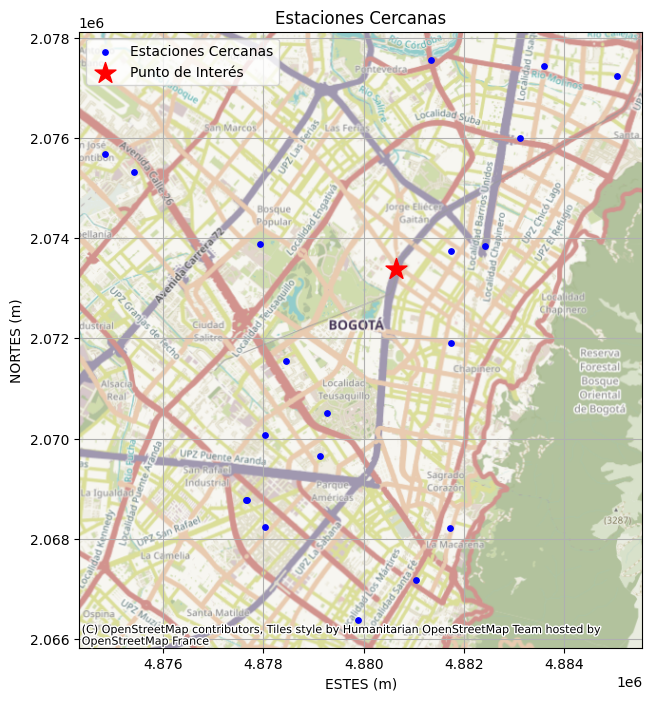

In [ ]:
import contextily as cx # https://geopandas.org/en/stable/gallery/plotting_basemap_background.html - https://contextily.readthedocs.io/en/latest/providers_deepdive.html
fig, ax = plt.subplots(figsize=(8, 8))

estaciones_cercanas.plot(
    ax=ax,
    marker="o",
    color="blue",
    label="Estaciones Cercanas",
    markersize=15,
    zorder = 2 # https://matplotlib.org/3.1.1/gallery/misc/zorder_demo.html
    )

# Convert punto_reproyectado (shapely Point) to a GeoSeries for plotting
ax.scatter(
    punto_reproyectado.x,
    punto_reproyectado.y,
    marker="*",
    color="red",
    label="Punto de Interés",
    s=250,
    zorder = 1)


cx.add_basemap(ax, crs=estaciones_cercanas.crs, source=cx.providers.OpenStreetMap.HOT)

ax.set_title("Estaciones Cercanas")
ax.set_xlabel("ESTES (m)")
ax.set_ylabel("NORTES (m)")
ax.grid(True)
ax.legend()
plt.show()

## 6 - Revisión de atributos relevantes - Análisis Exploratorio (EDA)

### 6.1 - Revision de estaciones duplicadas

In [ ]:
def buscar_estaciones_dupli(gdf_a_analizar):
    duplicadas = gdf_a_analizar[gdf_a_analizar.duplicated(subset="nombre",keep=False)]
    return duplicadas

In [ ]:
estaciones_duplicadas = buscar_estaciones_dupli(estaciones_cercanas)
estaciones_duplicadas

,CODIGO,nombre,CATEGORIA,TECNOLOGIA,ESTADO,FECHA_INST,altitud,latitud,longitud,DEPARTAMEN,...,d_DEPARTAM,d_MUNICIPI,d_AREA_OPE,d_AREA_HID,d_ZONA_HID,d_CORRIENT,d_SUBZONA_,geometry,distancia_m,distancia_km


### 6.2 - Limpieza por "Tipo" de estación

No todas las estaciones registran las precipitaciones, a continuación, se presenta un listados de estaciones que no debería ser tenidas en cuenta para el analisis de precipitacion ya que no registran este fenómeno.

### Categorías de estaciones meteorológicas del catálogo DHIME

El **Catálogo Nacional de Estaciones del IDEAM**, disponible a través de los servicios geográficos de DHIME, clasifica las estaciones mediante el campo `categoria`. Cada código corresponde a una categoría de estación definida de acuerdo con el tipo de observación hidrometeorológica realizada.

| Código | Categoría              |
| :----: | ---------------------- |
|  `AM`  | Agrometeorológica      |
|  `CO`  | Climática Ordinaria    |
|  `CP`  | Climática Principal    |
|  `LG`  | Limnigráfica           |
|  `LM`  | Limnimétrica           |
|  `ME`  | Meteorológica Especial |
|  `MM`  | Mareográfica           |
|  `PG`  | Pluviográfica          |
|  `PM`  | Pluviométrica          |
|  `RS`  | Radio Sonda            |
|  `SP`  | Sinóptica Principal    |
|  `SS`  | Sinóptica Secundaria   |

Para el presente estudio, esta clasificación permite identificar inicialmente las categorías de estaciones potencialmente relacionadas con el registro de precipitación, antes de aplicar los criterios espaciales y de disponibilidad temporal de las series.

**Fuente:** IDEAM – DHIME, *Catálogo Nacional de Estaciones*, servicio ArcGIS REST, capa `Catalogo Nacional de Estaciones`.

[Consultar fuente](https://dhime.ideam.gov.co/server/rest/services/CNE/Estaciones/MapServer/0). Consulta: agosto de 2026.


In [ ]:
categorias = estaciones_cercanas["CATEGORIA"].unique()
print(categorias)

['CO' 'ME' 'AB' 'CP' 'PM' 'RS' 'PG']


In [ ]:
categorias_candidatas = [
    "PM",  # Pluviométrica
    "PG",  # Pluviográfica
    "CO",  # Climática Ordinaria
    "CP",  # Climática Principal
    "ME",  # Meteorológica Especial
    "AB"   # Código no definido en el dominio consultado; se mantiene provisionalmente
]

In [ ]:
estaciones_cercanas = estaciones_cercanas.loc[estaciones_cercanas["CATEGORIA"].isin(categorias_candidatas)]
estaciones_cercanas.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 19 entries, 1493 to 2351
Data columns (total 33 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   CODIGO        19 non-null     object        
 1   nombre        19 non-null     object        
 2   CATEGORIA     19 non-null     object        
 3   TECNOLOGIA    19 non-null     object        
 4   ESTADO        19 non-null     object        
 5   FECHA_INST    19 non-null     datetime64[ms]
 6   altitud       19 non-null     float64       
 7   latitud       19 non-null     float64       
 8   longitud      19 non-null     float64       
 9   DEPARTAMEN    19 non-null     float64       
 10  MUNICIPIO     19 non-null     float64       
 11  AREA_OPERA    19 non-null     float64       
 12  AREA_HIDRO    19 non-null     float64       
 13  ZONA_HIDRO    19 non-null     float64       
 14  CORRIENTE     19 non-null     float64       
 15  FECHA_SUSP    13 non-null     date

In [ ]:
estaciones_cercanas["FECHA_INST_MOD"] = pd.to_datetime(estaciones_cercanas["FECHA_INST"],format="%d/%m/%Y",errors="coerce")
estaciones_cercanas["FECHA_SUSP_MOD"] = pd.to_datetime(estaciones_cercanas["FECHA_SUSP"],format="%d/%m/%Y",errors="coerce")
estaciones_cercanas.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 19 entries, 1493 to 2351
Data columns (total 35 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   CODIGO          19 non-null     object        
 1   nombre          19 non-null     object        
 2   CATEGORIA       19 non-null     object        
 3   TECNOLOGIA      19 non-null     object        
 4   ESTADO          19 non-null     object        
 5   FECHA_INST      19 non-null     datetime64[ms]
 6   altitud         19 non-null     float64       
 7   latitud         19 non-null     float64       
 8   longitud        19 non-null     float64       
 9   DEPARTAMEN      19 non-null     float64       
 10  MUNICIPIO       19 non-null     float64       
 11  AREA_OPERA      19 non-null     float64       
 12  AREA_HIDRO      19 non-null     float64       
 13  ZONA_HIDRO      19 non-null     float64       
 14  CORRIENTE       19 non-null     float64       
 15  

/usr/local/lib/python3.12/dist-packages/geopandas/geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/usr/local/lib/python3.12/dist-packages/geopandas/geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


In [ ]:
RUTA_INTERIM = PROJECT_ROOT / "data" / "raw"

ruta_geojson = RUTA_INTERIM / "estaciones_candidatas.geojson"

estaciones_cercanas.to_file(
    ruta_geojson,
    driver="GeoJSON",
)